In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
columns = df.columns
print(columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [5]:
for column in columns[:10]:
    print(f"column name: {column} {df[column].unique()}")
    print(f"Length: {len(df[column].unique())}")

column name: customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Length: 7043
column name: gender ['Female' 'Male']
Length: 2
column name: SeniorCitizen [0 1]
Length: 2
column name: Partner ['Yes' 'No']
Length: 2
column name: Dependents ['No' 'Yes']
Length: 2
column name: tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
Length: 73
column name: PhoneService ['No' 'Yes']
Length: 2
column name: MultipleLines ['No phone service' 'No' 'Yes']
Length: 3
column name: InternetService ['DSL' 'Fiber optic' 'No']
Length: 3
column name: OnlineSecurity ['No' 'Yes' 'No internet service']
Length: 3


In [6]:
for column in columns[10:]:
    print(f"column name: {column} {df[column].unique()}")
    print(f"Length: {len(df[column].unique())}")

column name: OnlineBackup ['Yes' 'No' 'No internet service']
Length: 3
column name: DeviceProtection ['No' 'Yes' 'No internet service']
Length: 3
column name: TechSupport ['No' 'Yes' 'No internet service']
Length: 3
column name: StreamingTV ['No' 'Yes' 'No internet service']
Length: 3
column name: StreamingMovies ['No' 'Yes' 'No internet service']
Length: 3
column name: Contract ['Month-to-month' 'One year' 'Two year']
Length: 3
column name: PaperlessBilling ['Yes' 'No']
Length: 2
column name: PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Length: 4
column name: MonthlyCharges [29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
Length: 1585
column name: TotalCharges ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Length: 6531
column name: Churn ['No' 'Yes']
Length: 2


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
print(f"Duplicated Data: {df.duplicated().sum()}")

Duplicated Data: 0


In [11]:
df = df.drop(columns=["customerID"])

In [12]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

In [14]:
print(f"Null Value in TotalCharges: {df['TotalCharges'].isnull().sum()}")

Null Value in TotalCharges: 11


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [16]:
print(f"Null Value in TotalCharges: {df['TotalCharges'].isnull().sum()}")

Null Value in TotalCharges: 0


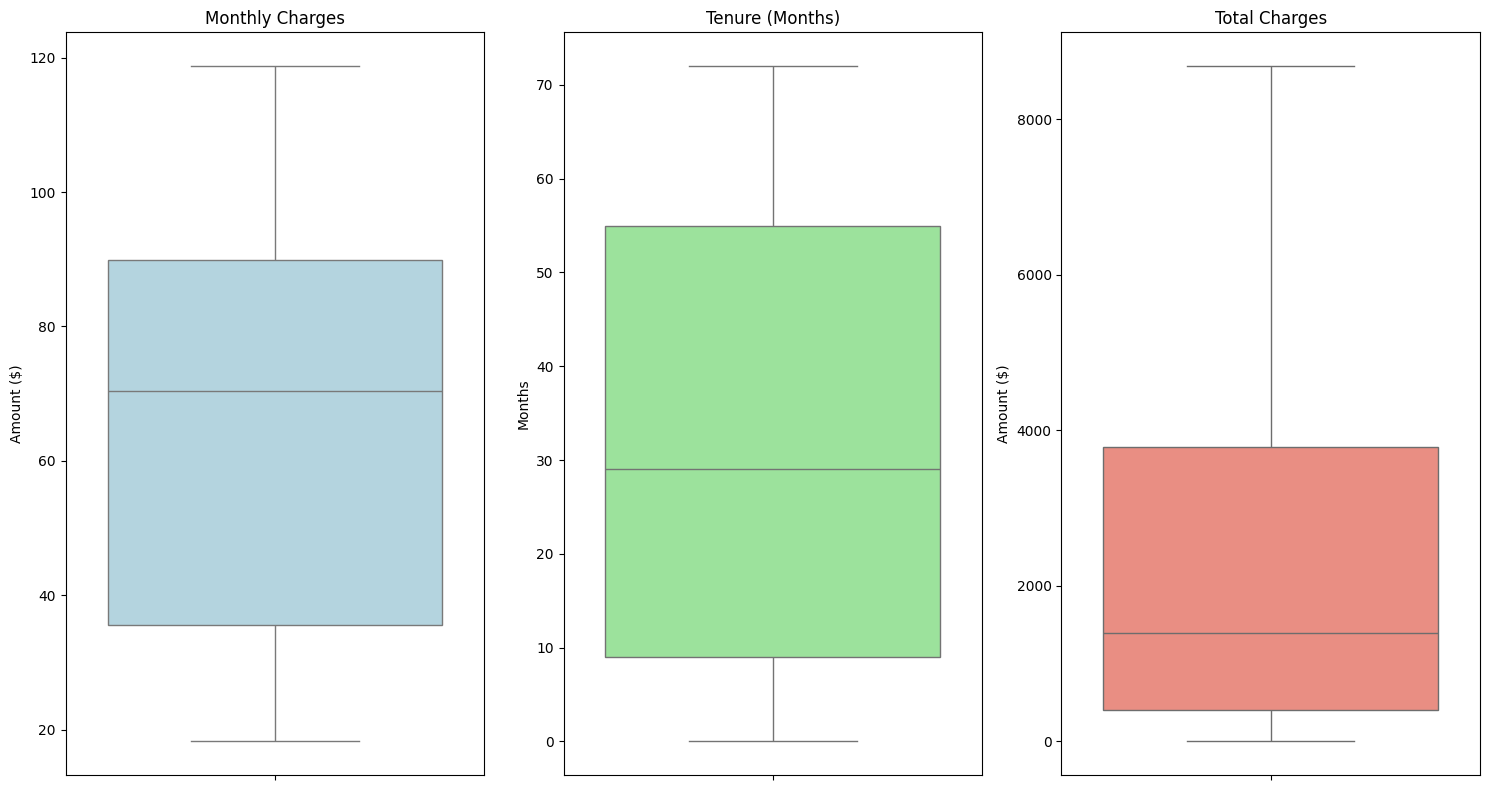

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

sns.boxplot(y=df["MonthlyCharges"], ax=axes[0] , color='lightblue')
axes[0].set_title('Monthly Charges')
axes[0].set_ylabel('Amount ($)')

sns.boxplot(y=df['tenure'], ax=axes[1], color='lightgreen')
axes[1].set_title('Tenure (Months)')
axes[1].set_ylabel('Months')

sns.boxplot(y=df['TotalCharges'], ax=axes[2], color='salmon')
axes[2].set_title('Total Charges')
axes[2].set_ylabel('Amount ($)')

plt.tight_layout()

plt.show()

In [18]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

C:\Users\new\AppData\Local\Temp\ipykernel_16288\3651206362.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df , x="Churn" , palette="Set2")


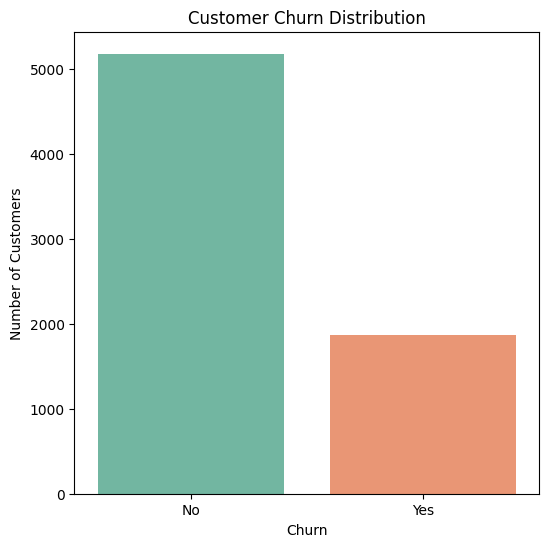

In [19]:
plt.figure(figsize=(6, 6))
sns.countplot(data=df , x="Churn" , palette="Set2")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

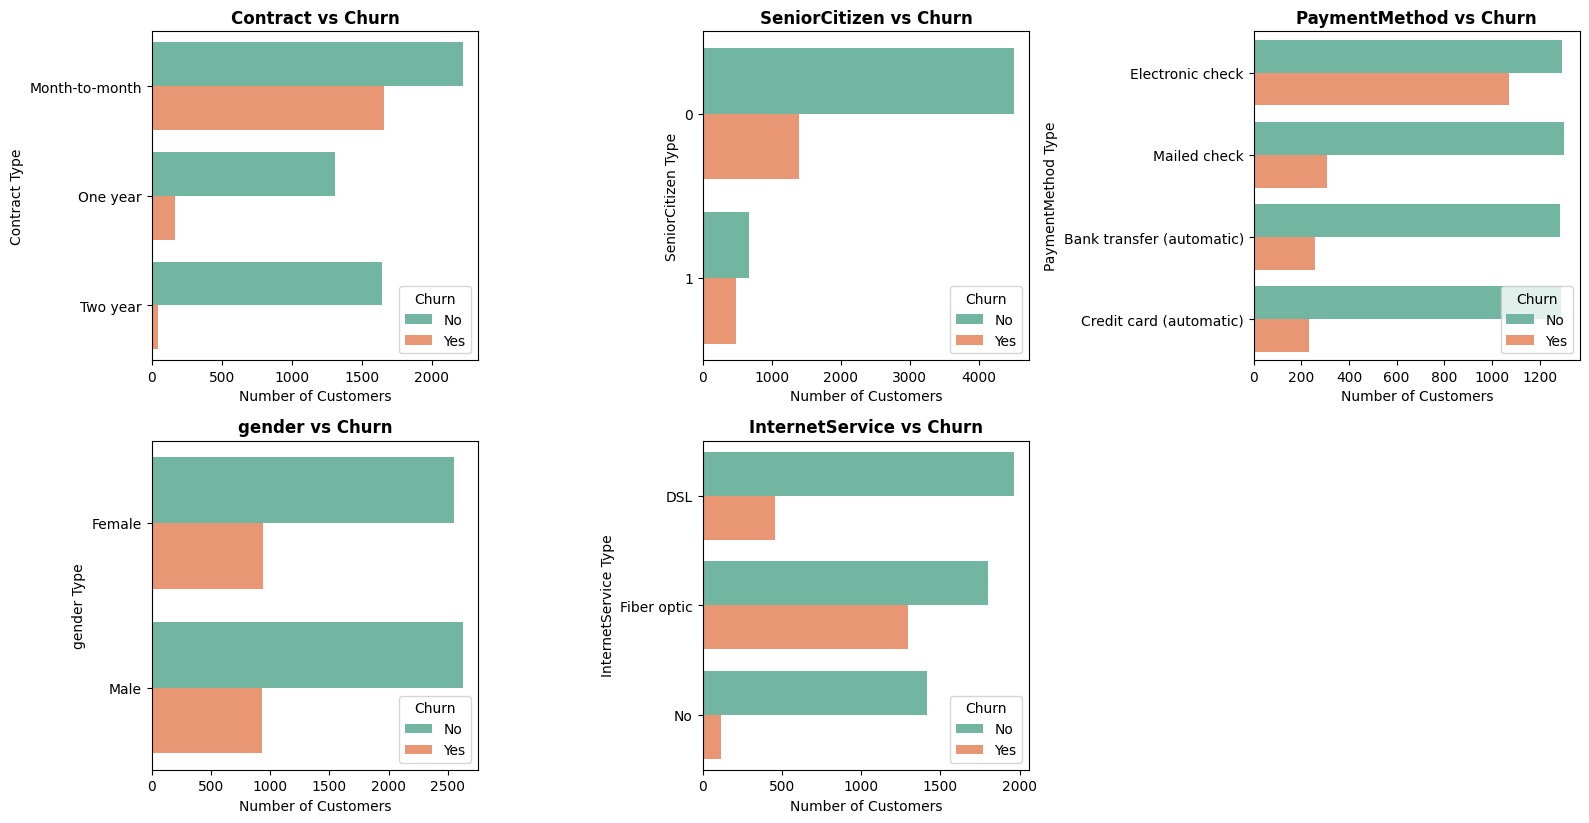

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))


columns = ["Contract" , "SeniorCitizen" , "PaymentMethod" , "gender" ,"InternetService"]

axes_flat = axes.flatten()

for i , col in enumerate(columns):
    sns.countplot(
        data=df, 
        y=df[col],
        hue="Churn", 
        ax=axes_flat[i],   
        palette="Set2"  
    )

    axes_flat[i].set_title(f'{col} vs Churn', fontsize=12, fontweight='bold')
    axes_flat[i].set_xlabel('Number of Customers')
    axes_flat[i].set_ylabel(f'{col} Type')
    
for j in range(len(columns), len(axes_flat)):
    fig.delaxes(axes_flat[j])
    
plt.tight_layout()
plt.show()

C:\Users\new\AppData\Local\Temp\ipykernel_16288\2756623707.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')


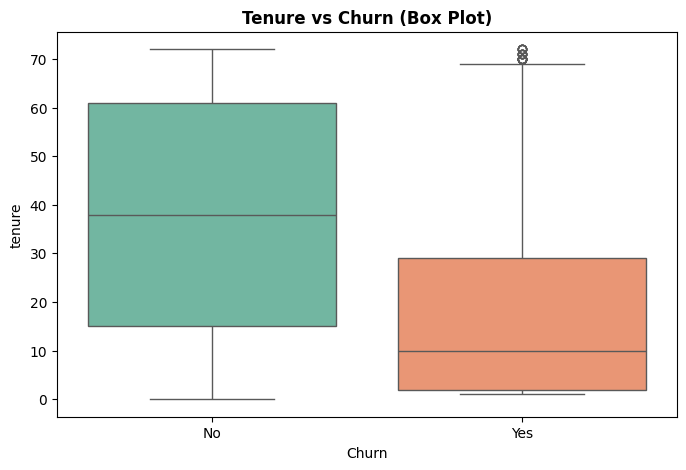

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')
plt.title('Tenure vs Churn (Box Plot)', fontsize=12, fontweight='bold')
plt.show()

C:\Users\new\AppData\Local\Temp\ipykernel_16288\4224093222.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')


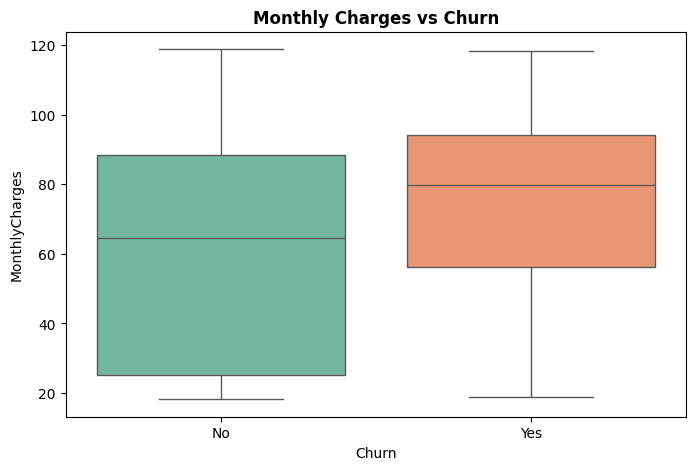

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')
plt.title('Monthly Charges vs Churn', fontsize=12, fontweight='bold')
plt.show()

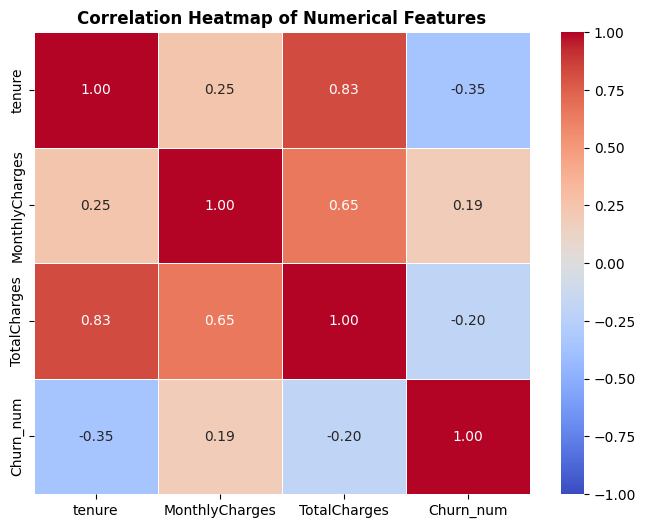

In [23]:
df['Churn_num'] = df['Churn'].map({'Yes': 1, 'No': 0})

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True,         
    cmap='coolwarm',    
    fmt=".2f",           
    linewidths=0.5,     
    vmin=-1, vmax=1 
)

plt.title('Correlation Heatmap of Numerical Features', fontsize=12, fontweight='bold')
plt.show()

In [24]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_num
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [25]:
df["Churn"] = df["Churn"].map({"Yes" : 1 , "No" : 0})

In [26]:
df = df.drop(columns="Churn_num")

In [27]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [28]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2, random_state=42 , stratify=y )

In [29]:
print(f"X Train Shape : {X_train.shape}")
print(f"X Test Shape : {X_test.shape}")
print(f"y Train Shape : {y_train.shape}")
print(f"y Test Shape : {y_test.shape}")

X Train Shape : (5634, 19)
X Test Shape : (1409, 19)
y Train Shape : (5634,)
y Test Shape : (1409,)


In [30]:
from sklearn.preprocessing import LabelEncoder
L = LabelEncoder()

In [31]:
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

for col in binary_cols:
    X_train[col] = L.fit_transform(X_train[col])
    X_test[col] = L.transform(X_test[col])

In [32]:
X_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,1,0,0,0,35,0,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,0,Electronic check,49.20,1701.65
3151,1,0,1,1,15,1,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,0,Mailed check,75.10,1151.55
4860,1,0,1,1,13,0,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,0,Mailed check,40.55,590.35
3867,0,0,1,0,26,1,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,1,Credit card (automatic),73.50,1905.70
3810,1,0,1,1,1,1,No,DSL,No,No,No,No,No,No,Month-to-month,0,Electronic check,44.55,44.55


In [33]:
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns
print("List Columns One-Hot Encoding:", list(categorical_cols))

List Columns One-Hot Encoding: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']


In [34]:
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

In [35]:
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

In [36]:
X_train_encoded = X_train_encoded.astype(int)
X_test_encoded = X_test_encoded.astype(int)

In [37]:
X_train_encoded.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,0,0,0,35,0,0,49,1701,1,...,0,0,1,0,1,0,0,0,1,0
3151,1,0,1,1,15,1,0,75,1151,0,...,0,0,0,0,0,0,0,0,0,1
4860,1,0,1,1,13,0,0,40,590,1,...,1,0,0,0,0,0,1,0,0,1
3867,0,0,1,0,26,1,1,73,1905,0,...,0,0,1,0,1,0,1,1,0,0
3810,1,0,1,1,1,1,0,44,44,0,...,0,0,0,0,0,0,0,0,1,0


In [38]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train_encoded[numerical_cols] = scaler.fit_transform(X_train_encoded[numerical_cols])
X_test_encoded[numerical_cols] = scaler.transform(X_test_encoded[numerical_cols])

In [39]:
X_train_encoded.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,0,0,0,0.102371,0,0,-0.513203,-0.262336,1,...,0,0,1,0,1,0,0,0,1,0
3151,1,0,1,1,-0.711743,1,0,0.349590,-0.503670,0,...,0,0,0,0,0,0,0,0,0,1
4860,1,0,1,1,-0.793155,0,0,-0.811863,-0.749831,1,...,1,0,0,0,0,0,1,0,0,1
3867,0,0,1,0,-0.263980,1,1,0.283222,-0.172823,0,...,0,0,1,0,1,0,1,1,0,0
3810,1,0,1,1,-1.281624,1,0,-0.679125,-0.989410,0,...,0,0,0,0,0,0,0,0,1,0


Model Name: Logistic Regression
Accuracy: 0.8070
Precision: 0.6604
Recall: 0.5615
F1-Score: 0.6069


 Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
 [[927 108]
 [164 210]]


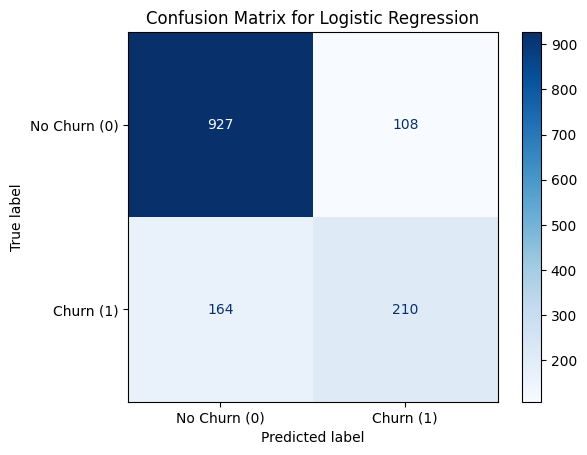

🎯 Train Accuracy: 80.56%
🎯 Test Accuracy:  80.70%
Model Name: Decision Tree
Accuracy: 0.7253
Precision: 0.4824
Recall: 0.4759
F1-Score: 0.4791


 Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.82      0.81      1035
           1       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.72      0.73      0.72      1409

Confusion Matrix:
 [[844 191]
 [196 178]]


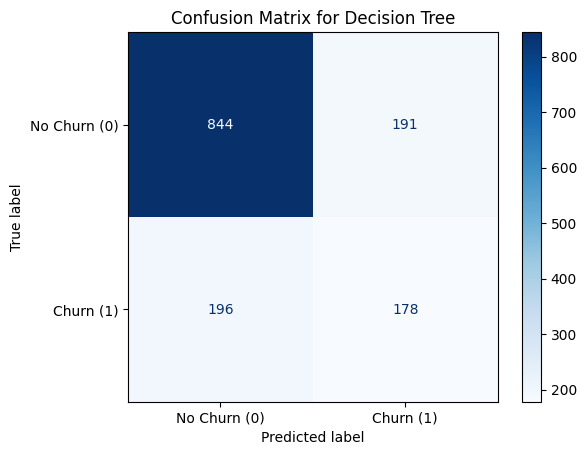

🎯 Train Accuracy: 99.11%
🎯 Test Accuracy:  72.53%
Model Name: Random Forest
Accuracy: 0.7814
Precision: 0.6138
Recall: 0.4759
F1-Score: 0.5361


 Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1035
           1       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409

Confusion Matrix:
 [[923 112]
 [196 178]]


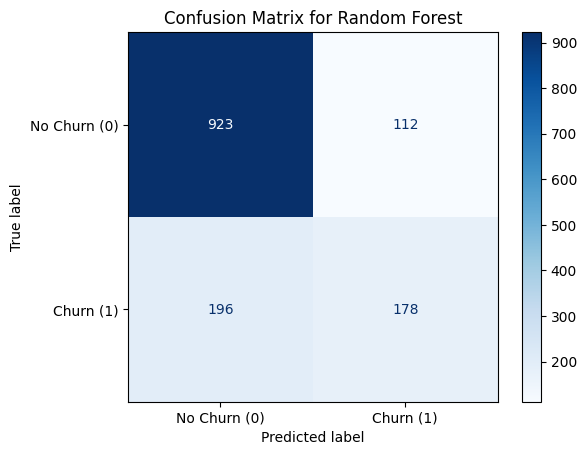

🎯 Train Accuracy: 99.11%
🎯 Test Accuracy:  78.14%
Model Name: XGBoost
Accuracy: 0.7821
Precision: 0.6044
Recall: 0.5187
F1-Score: 0.5583


 Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.86      1035
           1       0.60      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409

Confusion Matrix:
 [[908 127]
 [180 194]]


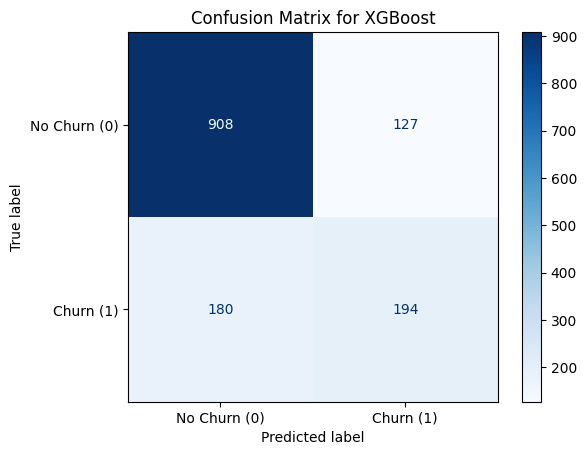

🎯 Train Accuracy: 92.99%
🎯 Test Accuracy:  78.21%


In [40]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

for name, model in models.items():
    print("=" * 50)
    print(f"Model Name: {name}")
    
    model.fit(X_train_encoded, y_train)
    
    y_pred = model.predict(X_test_encoded)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}\n")
    
    print("\n Classification Report:")
    print(classification_report(y_test, y_pred))
    
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn (0)', 'Churn (1)'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix for {name}")
    plt.show()
    
    y_train_pred = model.predict(X_train_encoded)
    y_test_pred = model.predict(X_test_encoded)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print(f"🎯 Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"🎯 Test Accuracy:  {test_accuracy * 100:.2f}%")

In [41]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_encoded, y_train)

Model Name: Logistic Regression
Accuracy: 0.7615
Precision: 0.5367
Recall: 0.7433
F1-Score: 0.6233


 Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1035
           1       0.54      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

Confusion Matrix:
 [[795 240]
 [ 96 278]]


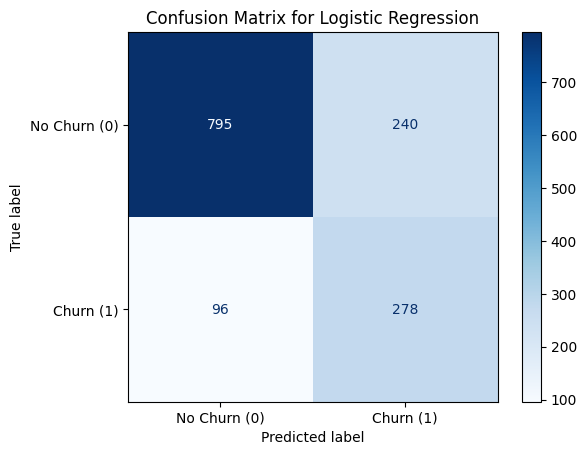

🎯 Train Accuracy: 76.09%
🎯 Test Accuracy:  76.15%
Model Name: Decision Tree
Accuracy: 0.7161
Precision: 0.4703
Recall: 0.5508
F1-Score: 0.5074


 Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80      1035
           1       0.47      0.55      0.51       374

    accuracy                           0.72      1409
   macro avg       0.65      0.66      0.65      1409
weighted avg       0.73      0.72      0.72      1409

Confusion Matrix:
 [[803 232]
 [168 206]]


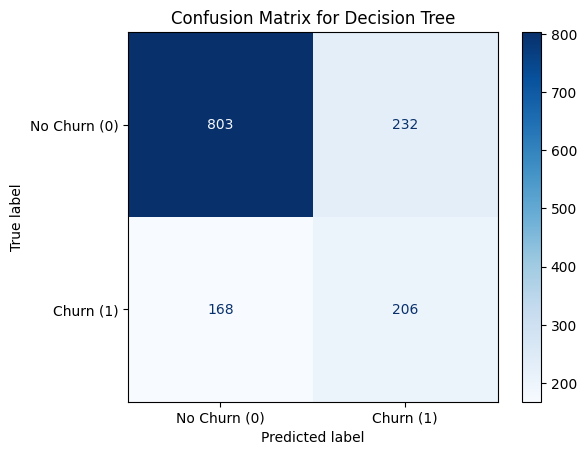

🎯 Train Accuracy: 98.99%
🎯 Test Accuracy:  71.61%
Model Name: Random Forest
Accuracy: 0.7672
Precision: 0.5520
Recall: 0.6524
F1-Score: 0.5980


 Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1035
           1       0.55      0.65      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

Confusion Matrix:
 [[837 198]
 [130 244]]


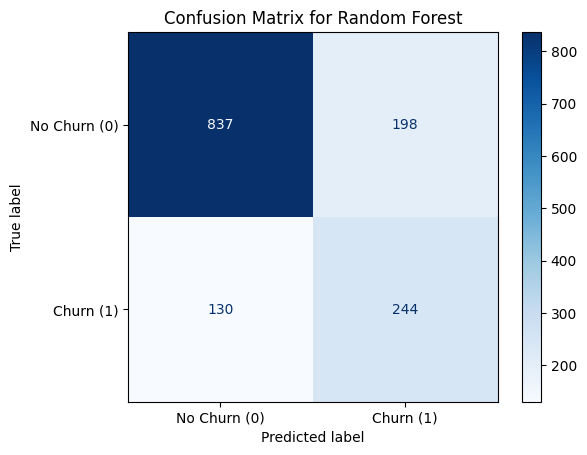

🎯 Train Accuracy: 98.95%
🎯 Test Accuracy:  76.72%
Model Name: XGBoost
Accuracy: 0.7587
Precision: 0.5370
Recall: 0.6604
F1-Score: 0.5923


 Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.79      0.83      1035
           1       0.54      0.66      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.73      0.71      1409
weighted avg       0.78      0.76      0.77      1409

Confusion Matrix:
 [[822 213]
 [127 247]]


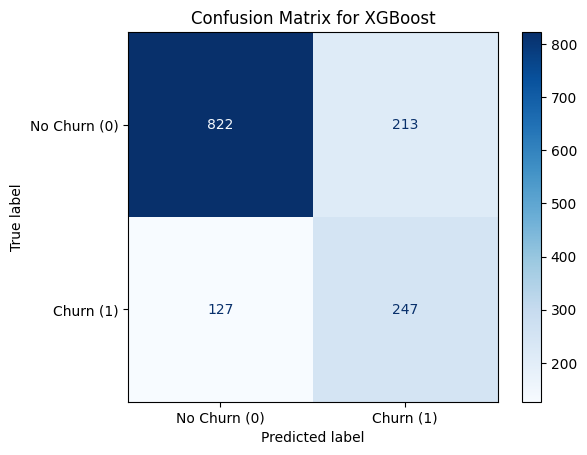

🎯 Train Accuracy: 91.32%
🎯 Test Accuracy:  75.87%


In [42]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

for name, model in models.items():
    print("=" * 50)
    print(f"Model Name: {name}")
    
    model.fit(X_train_resampled, y_train_resampled)
    
    y_pred = model.predict(X_test_encoded)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-Score: {f1:.4f}\n")
    
    print("\n Classification Report:")
    print(classification_report(y_test, y_pred))
    
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn (0)', 'Churn (1)'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix for {name}")
    plt.show()
    
    y_train_pred = model.predict(X_train_encoded)
    y_test_pred = model.predict(X_test_encoded)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print(f"🎯 Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"🎯 Test Accuracy:  {test_accuracy * 100:.2f}%")
    

In [43]:
import joblib

best_model = models["Logistic Regression"]
joblib.dump(best_model, 'best_churn_model.joblib')

print("✅f")

✅f


In [44]:
joblib.dump(scaler, 'scaler.joblib')

print("✅ Scaler saved successfully!")

✅ Scaler saved successfully!
